> **Recorded research notebook.** Executed outputs are retained from the completed study. Empirical recomputation requires the separately retained input snapshots described in `data/README.md`. Run `python scripts/reproduce_public.py` for checks and a synthetic demonstration using only this public repository. Historical publication-stage notes below describe the notebook execution date; the final PDF is now in `paper/final/Information-Diffusion-Final-Paper.pdf`.

# 06 · Robustness, reporting gates and research reflections

This notebook distinguishes completed checks from successful hypotheses. A method can be implemented correctly while the available data fail to identify its intended quantity. The resulting negative or inconclusive result remains part of the research.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'diffusion/common.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from diffusion.common import ROOT, design, sha256
from diffusion.reporting import table
from diffusion.presentation import show_table, show_json, show_figure, show_plot, equation
pd.set_option('display.max_columns', 12)
print('Project:', ROOT.name)
print('Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.')

Project: Information-Diffusion-Research
Clock: A02 audited seasonal mapping. Later sample: post-audit chronological transfer.


In [2]:
rows=[]
for phase in ['development','holdout','pooled']:
    d=json.loads((ROOT/f'outputs/adjustment-{phase}.json').read_text())
    for typ,item in d.items():
        g=item['gates']
        rows.append({'sample':phase.replace('holdout','later, post-audit'),'type':typ,'terminal':g['terminal_ci_excludes_zero'],'plateau':g['late_response_equivalence_heuristic'],'shape':g['shape_fit'],'interior':g['interior_parameters'],'bootstrap_valid':g['bootstrap_valid_fraction'],'coverage':item['sample']['adequate'],'reportable_speed':item['reportable']})
gates=pd.DataFrame(rows)
show_table(gates, 'Table N06.1. Speed-reporting gates for the primary SPX series.')
assert not gates.reportable_speed.any()
print('No empirical SPX statement or minutes speed passes every reporting gate.')
equation(18)

sample,type,terminal,plateau,shape,interior,bootstrap_valid,coverage,reportable_speed
development,Statements,True,False,True,True,0.960,False,False
development,Minutes,True,False,True,False,0.216,False,False
"later, post-audit",Statements,True,False,True,False,0.266,True,False
"later, post-audit",Minutes,False,False,False,False,0.548,True,False
pooled,Statements,True,True,True,True,0.834,False,False
pooled,Minutes,True,False,True,False,0.176,False,False


Equation (18). Plateau reporting diagnostic.
\mathrm{CI}_{0.90}(\beta_{20}-\beta_{10})\subset\left(-0.25|\hat\beta_{20}|,\ 0.25|\hat\beta_{20}|\right)
The margin depends on an estimated terminal response; this is a reporting heuristic, not a validated formal equivalence test.

No empirical SPX statement or minutes speed passes every reporting gate.


## Why an optimiser output is insufficient

The pooled statement curve has a finite numerical adjustment fit, but only 83.4% of the bootstrap curve fits satisfy the validity rule and pooled coverage is below 80%. Pooled minutes fail the plateau and interior-parameter rules, with only 17.6% of bootstrap curve fits valid. A raw fitted t90 is retained in diagnostic JSON for reproducibility; it is deliberately excluded from empirical headline results.

The bootstrap diagnostic fits only the first 199 of the 1,999 event-path draws, as declared in the implementation. Its interval, if reportable, would be conditional on passing shape checks. It does not turn a failed identification test into a precise speed. The estimated plateau margin is a heuristic, not a formally calibrated equivalence test.

measure,n,estimate,ci_low,ci_high
matched_day_placebo_20,48,1.246,-1.208,3.701
origin_shift_-1,49,-29.033,-39.730,-18.335
origin_shift_+1,49,-10.170,-20.027,-0.314
open_price_same_bar_labels,49,-28.936,-39.645,-18.226
boundary_open_0_to_20,49,-28.499,-39.954,-17.044
pre_return_volatility_controls,49,-25.402,-37.669,-13.136
exclude_any_flat_post_bar,43,-28.585,-39.580,-17.591
year_block_20_sensitivity,49,-29.458,-35.640,-15.268


measure,n,estimate,ci_low,ci_high
cumulative_10,49,-30.329,-39.704,-20.954
cumulative_15,49,-31.339,-44.024,-18.654
cumulative_20,49,-29.458,-40.306,-18.610
pre_placebo_60_10,49,2.021,-2.761,6.803


events,minimum_omission_slope,maximum_omission_slope,full_slope
49,-31.003,-25.698,-29.458


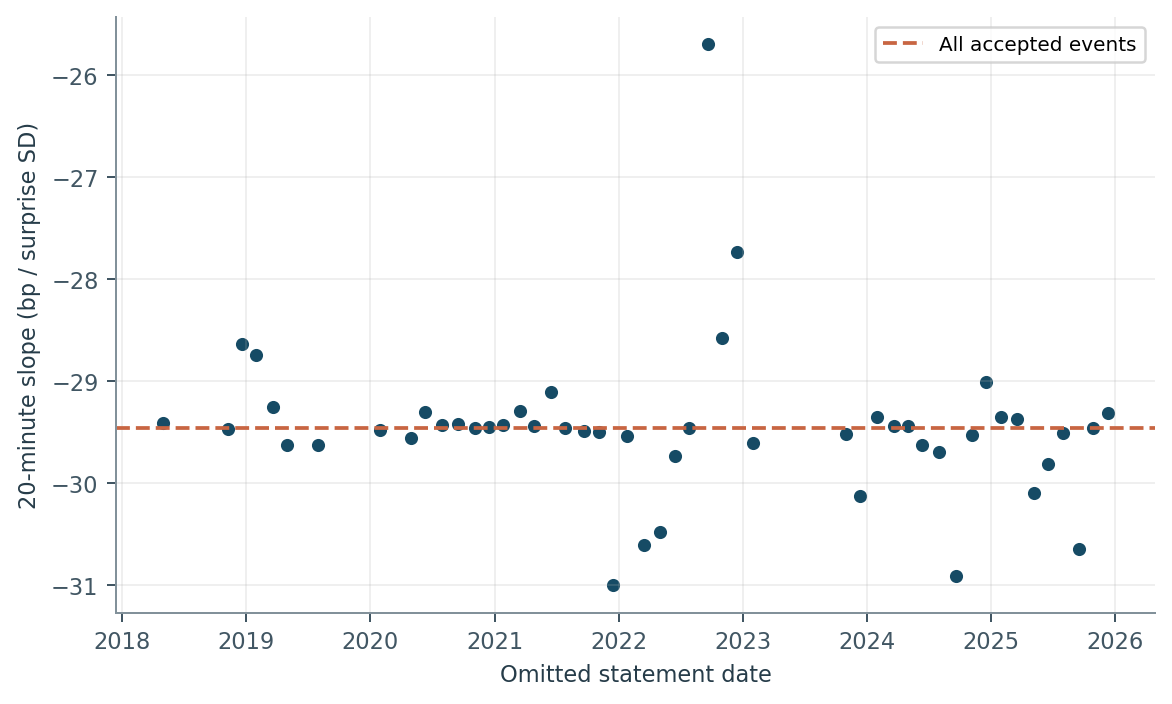

Figure 10. The pooled SPX 20-minute slope after omitting each accepted statement in turn. This evaluates event influence without removing inconvenient observations from the main estimate.

In [3]:
robust=table('robustness-pooled.csv').query("asset=='SPX' and event_type=='Statements'")
small=robust.query("measure!='leave_one_out'")
show_table(small[['measure','n','estimate','ci_low','ci_high']], 'Table N06.2. Pooled SPX statement robustness and placebo estimates.')
effects=table('effects-pooled.csv').query("asset=='SPX' and event_type=='Statements' and measure in ['cumulative_10','cumulative_15','cumulative_20','pre_placebo_60_10']")
show_table(effects[['measure','n','estimate','ci_low','ci_high']], 'Table N06.3. Alternative endpoints and the pre-event placebo.')
loo=robust.query("measure=='leave_one_out'")
show_table(pd.DataFrame([{'events':len(loo),'minimum_omission_slope':loo.estimate.min(),'maximum_omission_slope':loo.estimate.max(),'full_slope':loo.full_estimate.iloc[0]}]), 'Table N06.4. Complete leave-one-event-out range.')
assert len(loo)==49
show_figure(10)

## Observed failures and mitigations

1. **Daily acquisition was impractical.** The initial free Dukascopy daily-file route progressed too slowly for the planned panel. A01 moved to free annual HistData archives and changed the instrument interpretation to provider bid quotes. The original route and logs remain available.
2. **Documentation did not align the prices.** Published-window disagreement led to selected minute probes and the A02 seasonal clock rule. Both the original and corrected runs are retained. The clock mismatch is corrected globally, rather than by shifting individual events to their largest move.
3. **The original holdout was already seen.** The corrected development model was frozen before corrected later predictions. This preserves a chronological fit but does not restore untouched validation; the language and claims have been downgraded accordingly.
4. **Coverage remained inadequate.** The 2023 gaps and primary-series development exclusions were not repaired by the clock correction. Complete-window requirements and reporting gates were retained. NSX and EURUSD were not promoted after observing better coverage.
5. **A precise speed was unsupported.** Unstable bootstrap fits, absent plateaus, boundary estimates and coverage failures blocked empirical t50/t90 reporting. Unrestricted response curves remain the principal output.
6. **A plausible regressor could leak future information.** The −10-to-+20 factor is explicitly retrospective within that interval. The separate +20-to-+25 exercise is labelled idealised and is not a trading backtest.
7. **Simulation error was not uniformly nominal.** The 8.5% null rejection rate at N=80 was retained. Supplementary sample-size tests were added after the coverage audit and labelled accordingly.
8. **Bid-only data cannot validate execution.** No meaningful spread or volume analysis is possible. Open-price, endpoint and timestamp checks are retained, but they cannot replace missing ask quotes or execution records.

These are observed development events and limitations, not fabricated accounts of improvements that were never tested.

In [4]:
freeze=json.loads((ROOT/'protocol/corrected-model-freeze.json').read_text())
assert all(sha256(ROOT/p)==digest for p,digest in freeze['files'].items())
checks=json.loads((ROOT/'outputs/validation/checks.json').read_text())
show_json(checks)
assert checks['passed'] and checks['tests']==21
print('Analytical freeze unchanged after all notebook recomputations.')

{
  "executed_utc": "2026-10-16T20:28:44.951072+00:00",
  "tests": 21,
  "failures": 0,
  "errors": 0,
  "passed": true
}

Analytical freeze unchanged after all notebook recomputations.


## Remaining limitations

HC3 intervals are conditional on a frozen estimated factor and assume event-level independence; year-block resampling is only a sensitivity check with few blocks. Matched weekdays are observational controls, not randomised treatments. One-minute bid quotes cannot resolve second-level diffusion. A strict completeness rule protects alignment but can select a nonrepresentative sample. Dynamic fixed-effects lag tests have short-panel bias, while multiple exploratory comparisons have no global multiplicity adjustment.

## Milestone outcome

Every failed gate is visible. The analysis supports event-response measurement and a documented data-quality correction; it does not support a reliable single empirical diffusion speed.